# Project 3 — Diagnosing PINN Failure in Quantum-Mechanical Eigenvalue Problems

**Path:** B — Diagnosis  
**Research partner:** Dr. Houlong Zhuang, Arizona State University  
**Minimal case:** 1-D Schrödinger eigenvalue problem  
**Difficulty knob:** eigenstate number $n$

## Central question

> **How does the accuracy and reliability of a physics-informed neural network change as quantum eigenstate complexity increases, and are the observed failures caused primarily by insufficient neural-network expressivity or by physics-informed optimization?**

This notebook is the main project report. The reusable implementation lives in `src/`, experiment settings live in `config/experiment.json`, raw/processed numerical results live in `data/results/`, and figures live in `figures/`. The notebook therefore does **not** embed the experimental datasets manually.

## Rubric checklist

| Rubric category | Where addressed | Status |
|---|---|---|
| Outreach and interview (10) | Section 1 | Complete; **TODO:** outreach sequence |
| Problem brief (15) | Section 2 | Complete from interview notes|
| Minimal case formulation (15) | Section 3 | Complete PDE, BCs, normalization, simplifications, difficulty knob |
| Baseline and diagnostics P1–P5 (20) | Sections 5–9 | Complete |
| Path B findings (25) | Sections 7–10 | Failure sweep + controlled expressivity-vs-optimization experiment |
| Recommendation memo (5) | Section 11 | Draft complete; **TODO:** send and add response if received |
| Reproducibility (5) | Setup, `config/`, `src/`, `scripts/`, `data/` | Complete |
| Presentation and clarity (5) | Throughout | Organized as a single notebook; math renders in GitHub |

The course brief requires a credible conventional baseline, separate PINN loss diagnostics, error versus a difficulty knob, spatial/spectral error analysis, computational cost, and—specifically for Path B—a controlled experiment that separates candidate explanations for failure.

## How to reproduce or modify the experiment

The repository is organized so the report can be viewed immediately **without retraining** the PINNs, while still allowing each experiment to be regenerated.

```text
config/experiment.json
        ↓
src/ + scripts/
        ↓
data/solutions/ + data/results/
        ↓
figures/
        ↓
Project3_Report.ipynb
```

### Normal use
Leave the `RUN_...` switches below as `False`. The notebook loads the saved experimental CSV files committed to GitHub.

### Re-running with different settings
1. Change `config/experiment.json` — for example the states, seeds, network width, training epochs, or grid sizes.
2. Change the appropriate `RUN_...` switch to `True`, **or** run the corresponding script from the repository root.
3. Re-run this notebook to load/analyze the newly generated files.

This separates **configuration**, **implementation**, **raw results**, and **reporting**, so changing an experiment does not require manually editing result tables in the report.

In [1]:
# Repository setup and experiment switches
from pathlib import Path
import os, sys, json, subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image


def find_project_root(start=None):
    """Find the repository root by locating config/experiment.json and src/."""
    start = Path.cwd() if start is None else Path(start)
    candidates = [start, *start.parents]
    for candidate in candidates:
        if (candidate / "config" / "experiment.json").exists() and (candidate / "src").is_dir():
            return candidate.resolve()
    raise FileNotFoundError(
        "Could not find the project root. Put this notebook at the repository root "
        "beside config/, src/, data/, scripts/, and figures/."
    )

ROOT = find_project_root()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import load_config, resolve_path
from src.physics import exact_energy, exact_wavefunction_np
from src.finite_difference import solve_fd
from src.diagnostics import aggregate_sweep

CONFIG = load_config()
RESULTS_DIR = resolve_path(CONFIG, "results")
SOLUTIONS_DIR = resolve_path(CONFIG, "solutions")
FIGURES_DIR = resolve_path(CONFIG, "figures")
MODELS_DIR = resolve_path(CONFIG, "models")

# Keep these False for fast GitHub/report use. Turn on a stage only when you want to regenerate it.
RUN_P1_BASELINE = False
RUN_P3_SWEEP = False              # full neural sweep; can take several minutes
RUN_CONTROLLED_DIAGNOSIS = False  # supervised controls
RUN_P4_DIAGNOSTICS = False        # requires detailed P3 solution CSVs in data/solutions/
RUN_P5_COST = False

{k: v for k, v in CONFIG.items() if not k.startswith("_")}

{'problem': {'domain_length': 1.0, 'states': [1, 2, 3, 4, 5, 6, 8, 10]},
 'reproducibility': {'seeds': [0, 1, 2], 'torch_num_threads': 1},
 'network': {'width': 32, 'depth': 2, 'activation': 'tanh'},
 'finite_difference': {'grid_sizes': [50, 100, 250, 500, 1000],
  'final_n_interior': 1000,
  'n_states': 10,
  'timing_repeats': 25},
 'pinn': {'n_residual': 96,
  'n_quadrature': 257,
  'adam_epochs': 3000,
  'adam_lr': 0.001,
  'adam_lr_final': 0.0001,
  'lr_drop_fraction': 0.65,
  'lbfgs_max_iter': 60,
  'lbfgs_lr': 0.8,
  'lambda_energy': 0.01,
  'evaluation_points': 2001},
 'supervised_equal_budget': {'n_train': 257,
  'adam_epochs': 3000,
  'adam_lr': 0.001,
  'adam_lr_final': 0.0001,
  'lr_drop_fraction': 0.65,
  'lbfgs_max_iter': 60,
  'lbfgs_lr': 0.8,
  'evaluation_points': 2001},
 'supervised_capacity': {'n_train': 257,
  'adam_epochs': 6000,
  'adam_lr': 0.001,
  'adam_lr_final': 0.0001,
  'lr_drop_fraction': 0.65,
  'lbfgs_max_iter': 400,
  'lbfgs_lr': 0.8,
  'evaluation_point

In [2]:
# Optional stage regeneration. Each script reads config/experiment.json.
stages = [
    (RUN_P1_BASELINE, "scripts/run_p1_baseline.py"),
    (RUN_P3_SWEEP, "scripts/run_p3_sweep.py"),
    (RUN_CONTROLLED_DIAGNOSIS, "scripts/run_controlled_diagnosis.py"),
    (RUN_P4_DIAGNOSTICS, "scripts/run_p4_diagnostics.py"),
    (RUN_P5_COST, "scripts/run_p5_cost.py"),
]

for should_run, script in stages:
    if should_run:
        print(f"Running {script} ...")
        subprocess.run([sys.executable, script], check=True, cwd=ROOT)

print("Repository structure found; result files and reusable modules are available.")

Repository structure found; result files and reusable modules are available.


# 1. Outreach log

**Researcher:** Dr. Houlong Zhuang  
**Research area:** material discovery using atomic-scale / quantum-mechanical simulations and machine learning.

- **Researcher identified/reserved:** Asked after class on October 7th, 2026, initial email sent on October 10th, 2026.
- **Interview date:** October 19th, 2026.
- **Interview format/location:** In-person during office hours at his office in ERC385.
- **Team members present:** Kyle Swirski.
- **Problem brief reviewed by researcher:** Yes, on October 20th, 2026, after cleaning up the notes taken during the interview.

After not receiving a response to the initial email for over one week, he was asked after class if the interview could be conducted during office hours that same day, and he obliged the request. The interview focused on Dr. Zhuang's scientific goal, computational bottlenecks, existing machine-learning use, accuracy tradeoffs, and how quantum-mechanical eigenvalue problems enter his work.

The original email lives in `main/outreach.md` on GitHub.
> **Before submission:** Include initial email sent to Dr. Zhuang, if needed.

# 2. Problem brief

## Scientific problem and value

Dr. Zhuang's work uses atomic-scale simulation and machine learning to support **material discovery**. The broader goal is to understand how atomic configurations map to quantities such as energy and force, then use that information to screen candidate materials more efficiently. Faster or cheaper calculations could allow more material combinations to be evaluated before committing resources to expensive downstream simulation or experimentation.

## Governing computation and physical difficulty

The interview identified **eigenvalue problems associated with electron energies** as an important part of the quantum-mechanical computation. The full research problem includes a Hamiltonian with electron–electron, electron–nuclear, and nuclear–nuclear interactions. Electron interactions require approximation, and increasing the number of electrons increases the number of coefficients and the matrix size.

This produces a practical tradeoff:

- a smaller matrix solves quickly but may omit information needed for useful predictions;
- a larger matrix provides richer information but increases memory and wall-clock cost.

## Existing data / machine-learning context

The interview described two broad data regimes: expensive high-quality calculations that can require days and substantial CPU/GPU resources, and cheaper plentiful data of lower predictive quality. Dr. Zhuang's group has already used machine-learning surrogate approaches for semiconductor-related predictions, but accuracy remains a concern. The notes describe an approximate gap between a desired ability to resolve changes around **0.1 eV** and a current model accuracy around **0.2 eV**.

Dr. Zhuang also emphasized that useful accuracy is application dependent; there is no single percentage threshold that can be universally declared acceptable. He has reviewed the cleaned-up interview notes, and considers them to be acceptable for his current application.

## Project implication

Because the research group already uses machine learning and has observed accuracy/quality limitations, **Path B (Diagnosis)** is a better fit than simply demonstrating that a PINN can solve an easy problem. The purpose of this study is to isolate a simple quantum eigenvalue problem, deliberately increase its difficulty, reproduce PINN failure, and diagnose why it occurs.

# 3. Minimal case formulation — Path B

We reduce the full materials problem to the dimensionless 1-D infinite-square-well eigenproblem

$$
-\frac{d^2\psi}{dx^2}=E\psi, \qquad 0<x<L,
$$

with homogeneous Dirichlet boundary conditions

$$
\psi(0)=\psi(L)=0,
$$

and normalization

$$
\int_0^L \psi(x)^2\,dx = 1.
$$

For the experiments, $L=1$. The analytical eigenpairs are

$$
\boxed{\psi_n(x)=\sqrt{2}\sin(n\pi x)},
\qquad
\boxed{E_n=(n\pi)^2}.
$$

## Difficulty knob

The difficulty knob is the **eigenstate number**

$$
\boxed{n}.
$$

Increasing $n$ increases the spatial oscillation frequency of the eigenfunction. The final sweep uses

$$
n\in\{1,2,3,4,5,6,8,10\}.
$$

## Simplifications

The real problem is simplified from many interacting particles in a complex 3-D material environment to a single 1-D particle in an infinite square well. Electron–electron and realistic electron–nuclear interactions are omitted. This means the experiment **does not reproduce Dr. Zhuang's production calculations**.

The simplification intentionally preserves two features relevant to the interview:

1. an **energy eigenvalue/eigenfunction problem**, and
2. a controllable increase in **solution complexity**.

The objective is therefore diagnostic: determine how a standard PINN behaves as an eigenproblem becomes increasingly oscillatory.

# 4. Reusable numerical implementation

The implementation is intentionally kept outside the report notebook:

- `src/physics.py` — exact eigenvalues/eigenfunctions and error utilities
- `src/finite_difference.py` — conventional finite-difference eigensolver
- `src/models.py` — reusable fully connected network with hard boundary conditions
- `src/pinn.py` — projected/normalized PINN training and evaluation
- `src/supervised.py` — direct supervised capacity/control experiment
- `src/diagnostics.py` — aggregation and P4 error-spectrum analysis

The same network class is reused for PINN and supervised experiments, which strengthens the controlled comparison.

The main adjustable settings are stored in `config/experiment.json`, including states, seeds, network width/depth, residual points, optimizer budgets, and finite-difference grid sizes.

In [3]:
# Show the most important configuration values used for the saved experiment.
summary_config = {
    "domain_length": CONFIG["problem"]["domain_length"],
    "states": CONFIG["problem"]["states"],
    "seeds": CONFIG["reproducibility"]["seeds"],
    "network": CONFIG["network"],
    "finite_difference": CONFIG["finite_difference"],
    "pinn": CONFIG["pinn"],
    "controlled_states": CONFIG["controlled_states"],
}
summary_config

{'domain_length': 1.0,
 'states': [1, 2, 3, 4, 5, 6, 8, 10],
 'seeds': [0, 1, 2],
 'network': {'width': 32, 'depth': 2, 'activation': 'tanh'},
 'finite_difference': {'grid_sizes': [50, 100, 250, 500, 1000],
  'final_n_interior': 1000,
  'n_states': 10,
  'timing_repeats': 25},
 'pinn': {'n_residual': 96,
  'n_quadrature': 257,
  'adam_epochs': 3000,
  'adam_lr': 0.001,
  'adam_lr_final': 0.0001,
  'lr_drop_fraction': 0.65,
  'lbfgs_max_iter': 60,
  'lbfgs_lr': 0.8,
  'lambda_energy': 0.01,
  'evaluation_points': 2001},
 'controlled_states': [4, 8, 10]}

# 5. P1 — Conventional baseline

The baseline uses the centered second-order finite-difference approximation

$$
-\psi''(x_i)\approx \frac{-\psi_{i-1}+2\psi_i-\psi_{i+1}}{h^2},
$$

which produces the symmetric tridiagonal matrix eigenproblem

$$
H\boldsymbol\psi=E\boldsymbol\psi.
$$

The numerical eigenpairs are compared to the exact infinite-square-well solution, and the grid is refined from 50 to 1000 interior points.

,state_n,E_exact,E_FD,E_rel_error_percent,runtime_ms_first_10
0,1,9.869604,9.869596,0.000082,3.955463
4,5,246.740110,246.735047,0.002052,3.955463
9,10,986.960440,986.879431,0.008208,3.955463


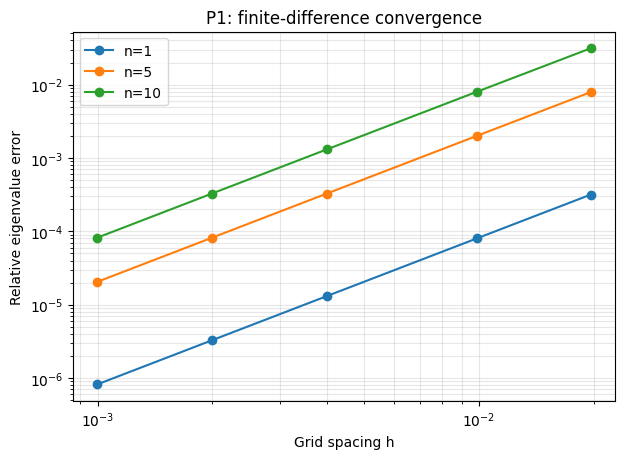

In [4]:
# Load saved P1 data from GitHub.
p1_conv = pd.read_csv(RESULTS_DIR / "p1_convergence_all_states.csv")
p1_final = pd.read_csv(RESULTS_DIR / "p1_final_grid_summary.csv")
p1_timing = pd.read_csv(RESULTS_DIR / "p1_timing.csv")

# Compact final-grid table for the report.
display(
    p1_final[p1_final["state_n"].isin([1, 5, 10])][
        ["state_n", "E_exact", "E_FD", "E_rel_error_percent", "runtime_ms_first_10"]
    ].round(8)
)

# Convergence plot generated from the saved CSV rather than hard-coded values.
fig, ax = plt.subplots(figsize=(7, 4.8))
for n in [1, 5, 10]:
    d = p1_conv[p1_conv.state_n == n].sort_values("h")
    ax.loglog(d.h, d.E_rel_error, "o-", label=f"n={n}")
ax.set_xlabel("Grid spacing h")
ax.set_ylabel("Relative eigenvalue error")
ax.set_title("P1: finite-difference convergence")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.show()

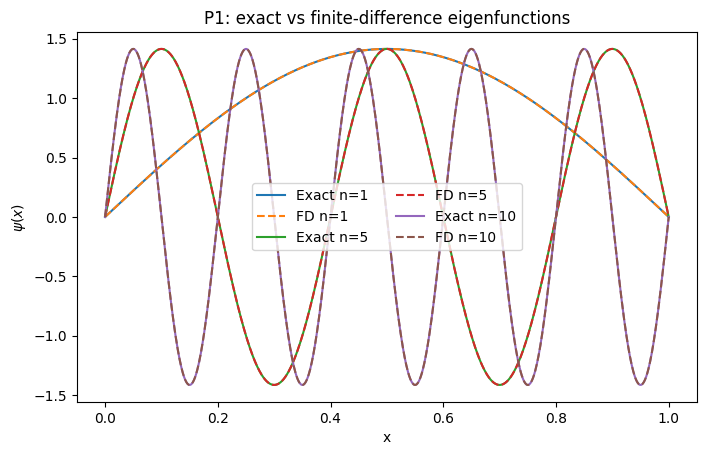

In [5]:
# Exact vs finite-difference eigenfunctions are inexpensive to regenerate directly.
N = CONFIG["finite_difference"]["final_n_interior"]
L = CONFIG["problem"]["domain_length"]
x_fd, E_fd, psi_fd = solve_fd(N, CONFIG["finite_difference"]["n_states"], L)

fig, ax = plt.subplots(figsize=(8, 4.8))
for n in [1, 5, 10]:
    ax.plot(x_fd, exact_wavefunction_np(n, x_fd, L), label=f"Exact n={n}")
    ax.plot(x_fd, psi_fd[:, n-1], "--", label=f"FD n={n}")
ax.set_xlabel("x")
ax.set_ylabel(r"$\psi(x)$")
ax.set_title("P1: exact vs finite-difference eigenfunctions")
ax.legend(ncol=2)
plt.show()

### P1 result

At the final $N=1000$ grid, the eigenvalue error is approximately **0.000082% for $n=1$** and **0.00821% for $n=10$**. The convergence curve follows the expected second-order behavior. The conventional method therefore provides a credible, highly accurate reference solution for the neural experiments.

# 6. P2 — Loss components and easy-case verification

Before interpreting higher-state failures, the neural solver was checked on easy states and its loss components were recorded separately during training.

The final eigenstate formulation uses:

- a hard boundary transform, so boundary error is essentially zero;
- projection against lower states, so orthogonality is enforced to numerical tolerance;
- internal normalization, so the wavefunction norm remains approximately one;
- a PDE residual plus a small Rayleigh-energy selection term as the optimized objective.

This makes the PDE residual the main nontrivial training diagnostic while still allowing all relevant constraint quantities to be logged.

In [6]:
# Ground-state multi-seed verification comes from a separate saved CSV.
p2_ground = pd.read_csv(RESULTS_DIR / "p2_multiseed_summary.csv")
display(
    p2_ground[["seed", "energy_pinn", "energy_error_percent", "wavefunction_error_percent",
               "pde_loss", "normalization_integral"]].round(8)
)

,seed,energy_pinn,energy_error_percent,wavefunction_error_percent,pde_loss,normalization_integral
0,0,9.869568,0.000370,0.002973,0.000080,0.999988
1,1,9.869571,0.000341,0.002787,0.000066,0.999987
2,2,9.869567,0.000380,0.000934,0.000011,0.999996


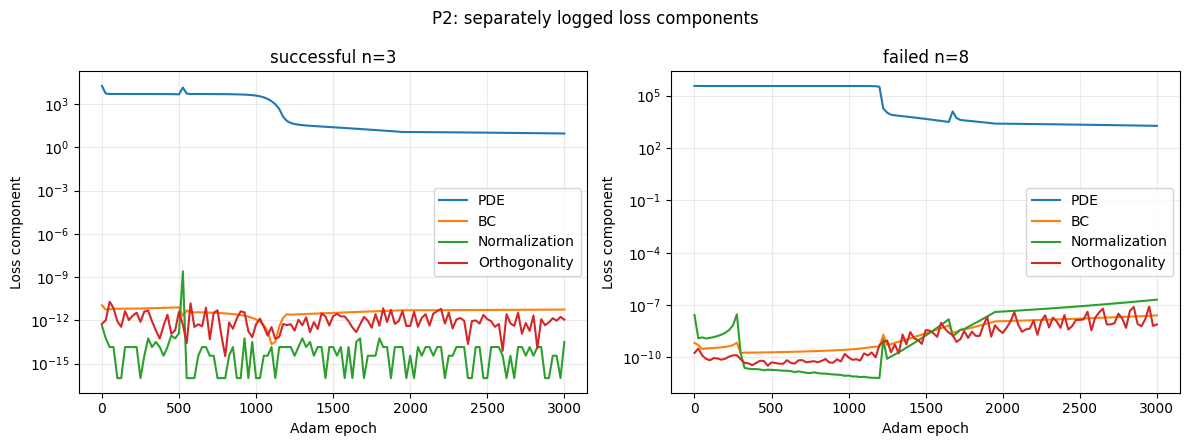

In [7]:
# Loss histories are saved as separate CSVs, not embedded in the notebook.
loss_files = {
    "successful n=3": RESULTS_DIR / "hist_n3_loss_history.csv",
    "failed n=8": RESULTS_DIR / "hist_n8_fail_loss_history.csv",
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (label, path) in zip(axes, loss_files.items()):
    if not path.exists():
        ax.text(0.5, 0.5, f"Missing {path.name}\nUse the updated support package or regenerate training history.",
                ha="center", va="center")
        ax.set_axis_off()
        continue
    hist = pd.read_csv(path)
    for col, name in [
        ("pde_loss", "PDE"),
        ("bc_loss", "BC"),
        ("normalization_loss", "Normalization"),
        ("orthogonality_loss", "Orthogonality"),
    ]:
        if col in hist.columns:
            y = np.maximum(hist[col].to_numpy(float), 1e-16)
            ax.semilogy(hist.epoch, y, label=name)
    ax.set_xlabel("Adam epoch")
    ax.set_ylabel("Loss component")
    ax.set_title(label)
    ax.grid(True, which="both", alpha=0.25)
    ax.legend()
plt.suptitle("P2: separately logged loss components")
plt.tight_layout()
plt.show()

### P2 interpretation

The easy-state checks confirm that the neural formulation can solve low eigenstates before the difficulty is increased. The logged constraints remain near numerical tolerance, while the PDE residual becomes much larger and harder to reduce in failed high-state runs. This prevents a small constraint loss from being mistaken for a correct physical solution.

# 7. P3 — Error versus difficulty knob

The central difficulty sweep keeps the architecture and training procedure fixed while increasing

$$
n=1,2,3,4,5,6,8,10.
$$

Three random seeds are used for each state. The primary metric is relative wavefunction $L^2$ error, with eigenvalue error and training time recorded as additional diagnostics.

In [8]:
# Load raw P3 runs. All aggregate statistics below are generated dynamically from the raw file.
p3 = pd.read_csv(RESULTS_DIR / "p3_full_sweep_all_runs.csv")

p3_agg = (
    p3.groupby("target_n")
      .agg(
          wavefunction_error_mean_percent=("wavefunction_error_percent", "mean"),
          wavefunction_error_median_percent=("wavefunction_error_percent", "median"),
          wavefunction_error_std_percent=("wavefunction_error_percent", "std"),
          wavefunction_error_min_percent=("wavefunction_error_percent", "min"),
          wavefunction_error_max_percent=("wavefunction_error_percent", "max"),
          energy_error_median_percent=("energy_error_percent", "median"),
          median_training_s=("training_time_s", "median"),
          runs_total=("wavefunction_error_percent", "size"),
      )
      .reset_index()
      .rename(columns={"target_n": "n"})
)

p3_agg["runs_below_5pct"] = p3.groupby("target_n")["wavefunction_error_percent"].apply(lambda x: (x < 5).sum()).to_numpy()
display(p3_agg.round(5))

,n,wavefunction_error_mean_percent,wavefunction_error_median_percent,wavefunction_error_std_percent,wavefunction_error_min_percent,wavefunction_error_max_percent,energy_error_median_percent,median_training_s,runs_total,runs_below_5pct
0,1,0.01156,0.00954,0.00461,0.00830,0.01684,0.00001,19.37682,3,3
1,2,0.03051,0.04089,0.02060,0.00679,0.04386,0.00006,22.61298,3,3
2,3,0.23541,0.18804,0.08446,0.18527,0.33293,0.00144,22.80156,3,3
3,4,6.83259,4.42691,4.62017,3.91166,12.15921,0.15203,13.70653,3,2
4,5,12.91319,17.92822,8.77759,2.77788,18.03346,1.50829,19.20289,3,1
5,6,3.51431,3.94730,1.84542,1.49089,5.10473,0.08898,19.45077,3,2
6,8,13.21158,16.85002,11.47558,0.35787,22.42687,0.83664,18.03778,3,1
7,10,47.78485,27.08890,37.41474,25.29045,90.97519,3.05695,22.39052,3,0


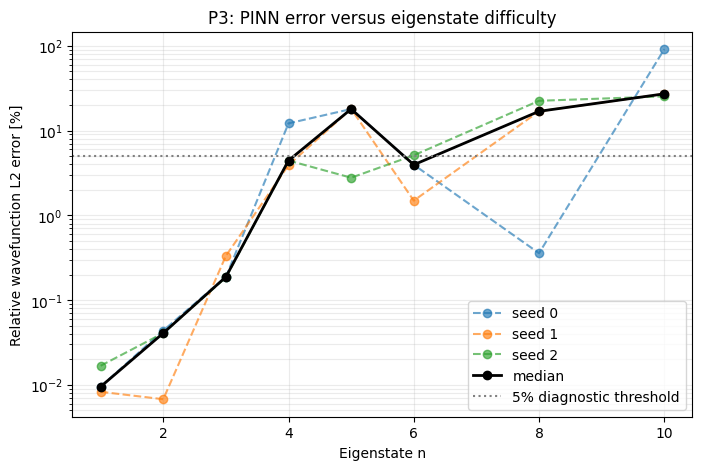

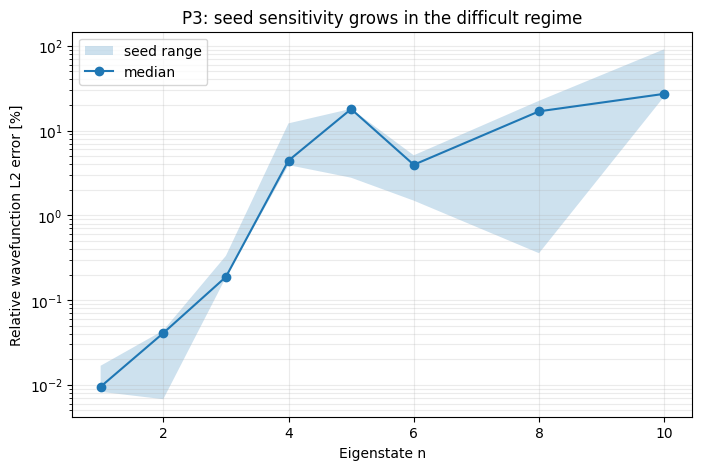

In [9]:
# P3 main plots generated from the raw saved data.
fig, ax = plt.subplots(figsize=(8, 5))
for seed in sorted(p3.seed.unique()):
    d = p3[p3.seed == seed].sort_values("target_n")
    ax.semilogy(d.target_n, d.wavefunction_error_percent, "o--", alpha=0.65, label=f"seed {seed}")
ax.semilogy(p3_agg.n, p3_agg.wavefunction_error_median_percent, "ko-", linewidth=2, label="median")
ax.axhline(5, color="gray", linestyle=":", label="5% diagnostic threshold")
ax.set_xlabel("Eigenstate n")
ax.set_ylabel("Relative wavefunction L2 error [%]")
ax.set_title("P3: PINN error versus eigenstate difficulty")
ax.grid(True, which="both", alpha=0.25)
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.fill_between(
    p3_agg.n,
    p3_agg.wavefunction_error_min_percent,
    p3_agg.wavefunction_error_max_percent,
    alpha=0.22,
    label="seed range",
)
ax.semilogy(p3_agg.n, p3_agg.wavefunction_error_median_percent, "o-", label="median")
ax.set_xlabel("Eigenstate n")
ax.set_ylabel("Relative wavefunction L2 error [%]")
ax.set_title("P3: seed sensitivity grows in the difficult regime")
ax.grid(True, which="both", alpha=0.25)
ax.legend()
plt.show()

### P3 result

- $n=1,2,3$ are consistently accurate.
- The first clear reliability transition appears around **$n=4$**.
- At $n=8$, the same architecture and training budget produce approximately **0.36%**, **16.85%**, and **22.43%** error depending only on seed.
- At $n=10$, all three seeds fail badly, with approximately **25–91%** wavefunction error.

The behavior is therefore not a simple smooth frequency cutoff. Instead, higher states produce **strong optimization sensitivity and unreliable convergence**.

# 8. Path B controlled experiment — expressivity vs. physics-informed optimization

Path B requires a controlled experiment that distinguishes competing explanations. Two hypotheses are considered:

1. **Expressivity limitation:** the 1–32–32–1 tanh network cannot represent higher eigenfunctions.
2. **Physics-informed optimization limitation:** the architecture can represent them, but the PINN loss does not reliably find the correct solution.

The same basic network architecture is therefore trained **directly** on the exact wavefunction for $n=4,8,10$.

Two controls are reported:

- **Equal budget:** approximately the same optimizer budget as the PINN.
- **Capacity test:** a longer supervised optimization whose purpose is to test whether the architecture can represent the waveform at all.

,n,median,mean,min,max,method
0,4,4.42691,6.83259,3.91166,12.15921,PINN
1,8,16.85002,13.21158,0.35787,22.42687,PINN
2,10,27.08890,47.78485,25.29045,90.97519,PINN
3,4,2.82869,3.89843,2.28576,6.58084,Supervised — equal budget
4,8,4.36238,3.65056,2.19292,4.39639,Supervised — equal budget
5,10,5.25159,6.66158,2.83116,11.90198,Supervised — equal budget
6,4,0.58096,0.59207,0.39914,0.79611,Supervised — capacity test
7,8,0.30508,0.25965,0.15592,0.31796,Supervised — capacity test
8,10,0.32003,0.31565,0.26952,0.35741,Supervised — capacity test


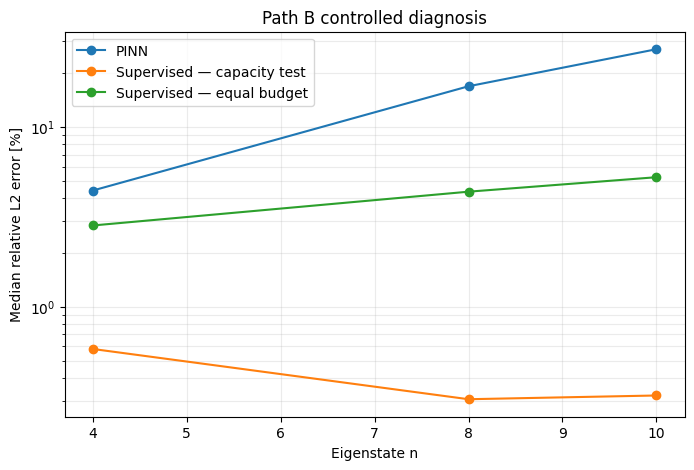

In [10]:
# Build the controlled comparison dynamically from raw CSV files.
controlled_states = CONFIG["controlled_states"]
pinn_control = p3[p3.target_n.isin(controlled_states)].copy()
sup_equal = pd.read_csv(RESULTS_DIR / "supervised_equal_budget_all_runs.csv")
sup_capacity = pd.read_csv(RESULTS_DIR / "supervised_capacity_all_runs.csv")

def summarize_method(df, label):
    s = (
        df.groupby("target_n")["wavefunction_error_percent"]
          .agg(["median", "mean", "min", "max"])
          .reset_index()
          .rename(columns={"target_n": "n"})
    )
    s["method"] = label
    return s

control_summary = pd.concat([
    summarize_method(pinn_control, "PINN"),
    summarize_method(sup_equal, "Supervised — equal budget"),
    summarize_method(sup_capacity, "Supervised — capacity test"),
], ignore_index=True)

display(control_summary.round(5))

fig, ax = plt.subplots(figsize=(8, 5))
for method, d in control_summary.groupby("method"):
    ax.semilogy(d.n, d["median"], "o-", label=method)
ax.set_xlabel("Eigenstate n")
ax.set_ylabel("Median relative L2 error [%]")
ax.set_title("Path B controlled diagnosis")
ax.grid(True, which="both", alpha=0.25)
ax.legend()
plt.show()

### Controlled-experiment conclusion

The supervised capacity-test medians are approximately **0.581% ($n=4$)**, **0.305% ($n=8$)**, and **0.320% ($n=10$)**. The corresponding PINN medians are approximately **4.43%**, **16.85%**, and **27.09%**.

At $n=10$, the PINN median error is therefore roughly **85 times larger** than the supervised capacity-test error. Even under the equal-budget supervised comparison, direct training remains substantially more accurate than the PINN at the difficult states.

Because the same architecture can represent these wavefunctions accurately when trained directly,

$$
\boxed{\text{insufficient network expressivity is not the primary cause of the observed PINN failure.}}
$$

The evidence instead favors **physics-informed optimization / loss-landscape difficulty** as the dominant limitation.

# 9. P4 — Where is the error?

For representative successful and failed cases, the pointwise error is

$$
e(x)=\psi_{PINN}(x)-\psi_{exact}(x).
$$

The error is analyzed both with an FFT and by projection onto the natural Dirichlet sine eigenbasis

$$
\phi_m(x)=\sqrt{2}\sin(m\pi x).
$$

The sine-basis decomposition is especially appropriate because these functions are the eigenmodes of the simplified quantum problem.

In [11]:
# Load P4 diagnostic tables from separate files.
p4_summary = pd.read_csv(RESULTS_DIR / "p4_error_spectrum_summary.csv")
p4_modes = pd.read_csv(RESULTS_DIR / "p4_sine_mode_coefficients.csv")

display(
    p4_summary[[
        "case", "relative_L2_percent", "max_abs_error",
        "FFT_peak_frequency_cycles_per_unit",
        "sine_lower_modes_fraction_of_error_energy_percent",
        "sine_higher_modes_1_to_30_fraction_of_error_energy_percent",
    ]].round(5)
)

,case,relative_L2_percent,max_abs_error,FFT_peak_frequency_cycles_per_unit,sine_lower_modes_fraction_of_error_energy_percent,sine_higher_modes_1_to_30_fraction_of_error_energy_percent
0,"n=2, seed 1 (easy)",0.00679,0.00013,4.0,0.00000,99.95545
1,"n=8, seed 0 (successful)",0.37000,0.01180,4.0,0.00658,99.69072
2,"n=8, seed 2 (failed)",22.42687,0.35025,5.0,0.00001,98.71964
3,"n=10, seed 1 (failed)",31.32608,0.63631,5.0,0.00000,97.48546
4,"n=10, seed 0 (severe failure)",90.97519,1.32125,5.0,0.00022,0.08789


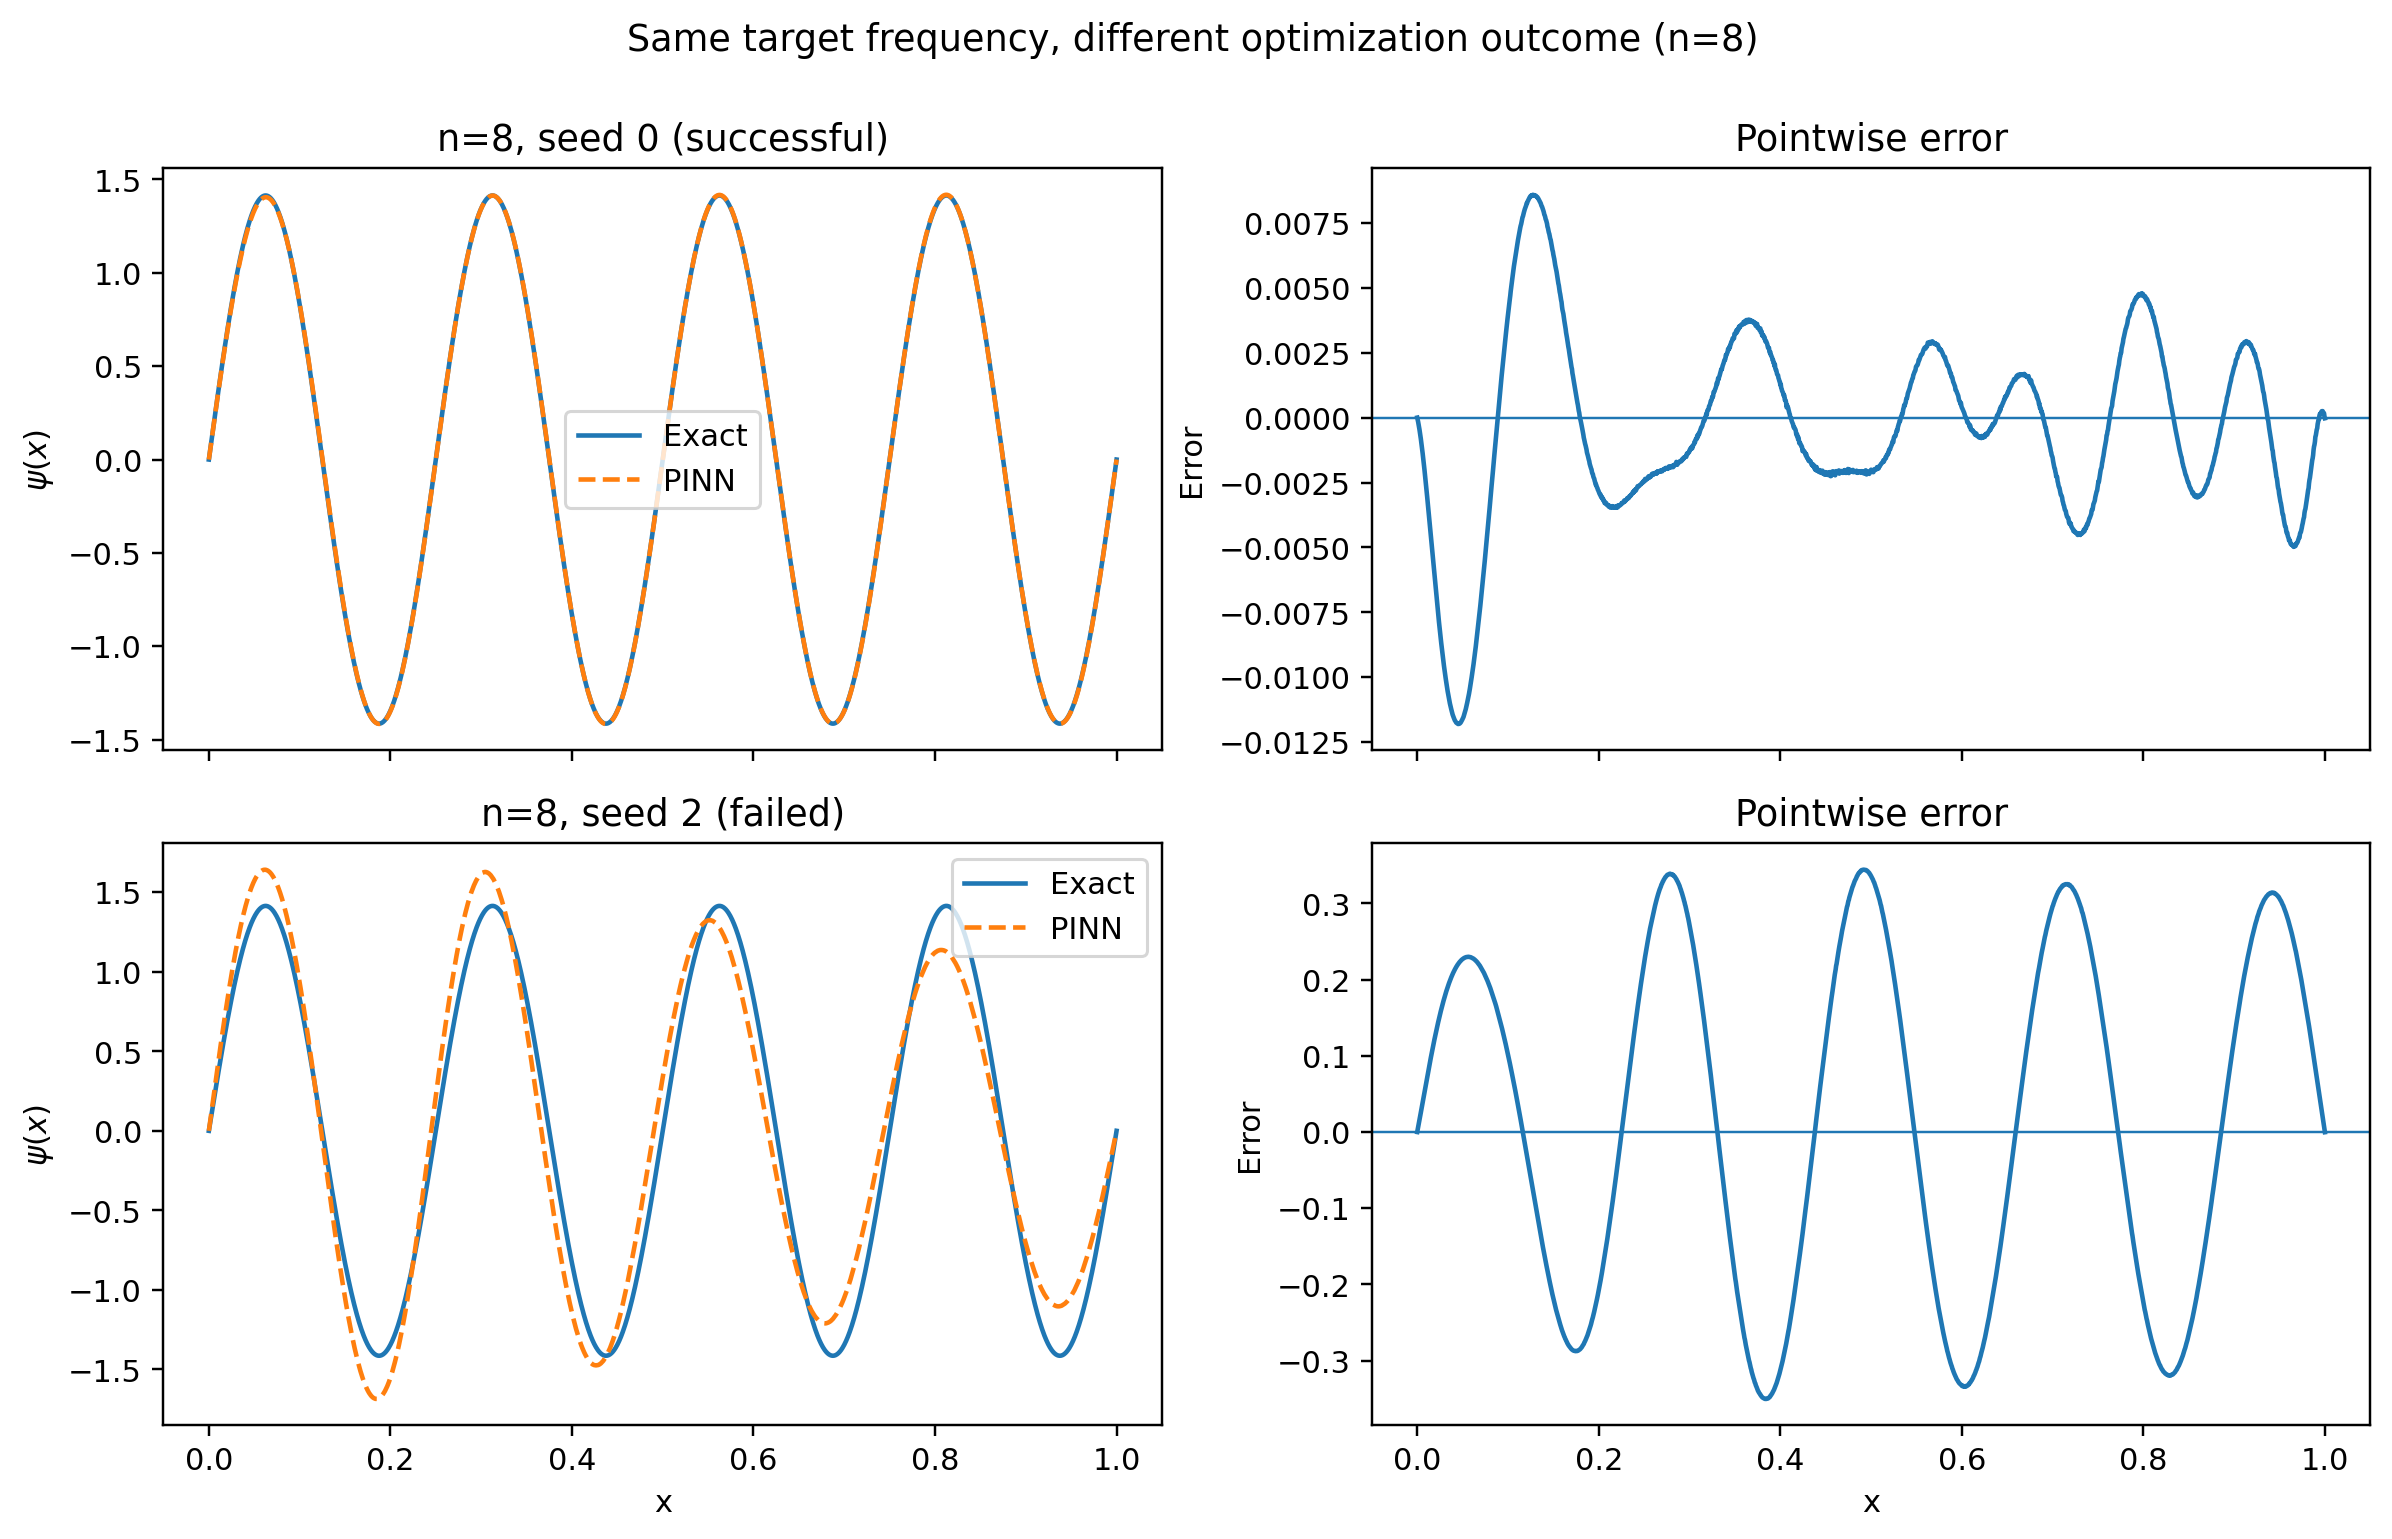

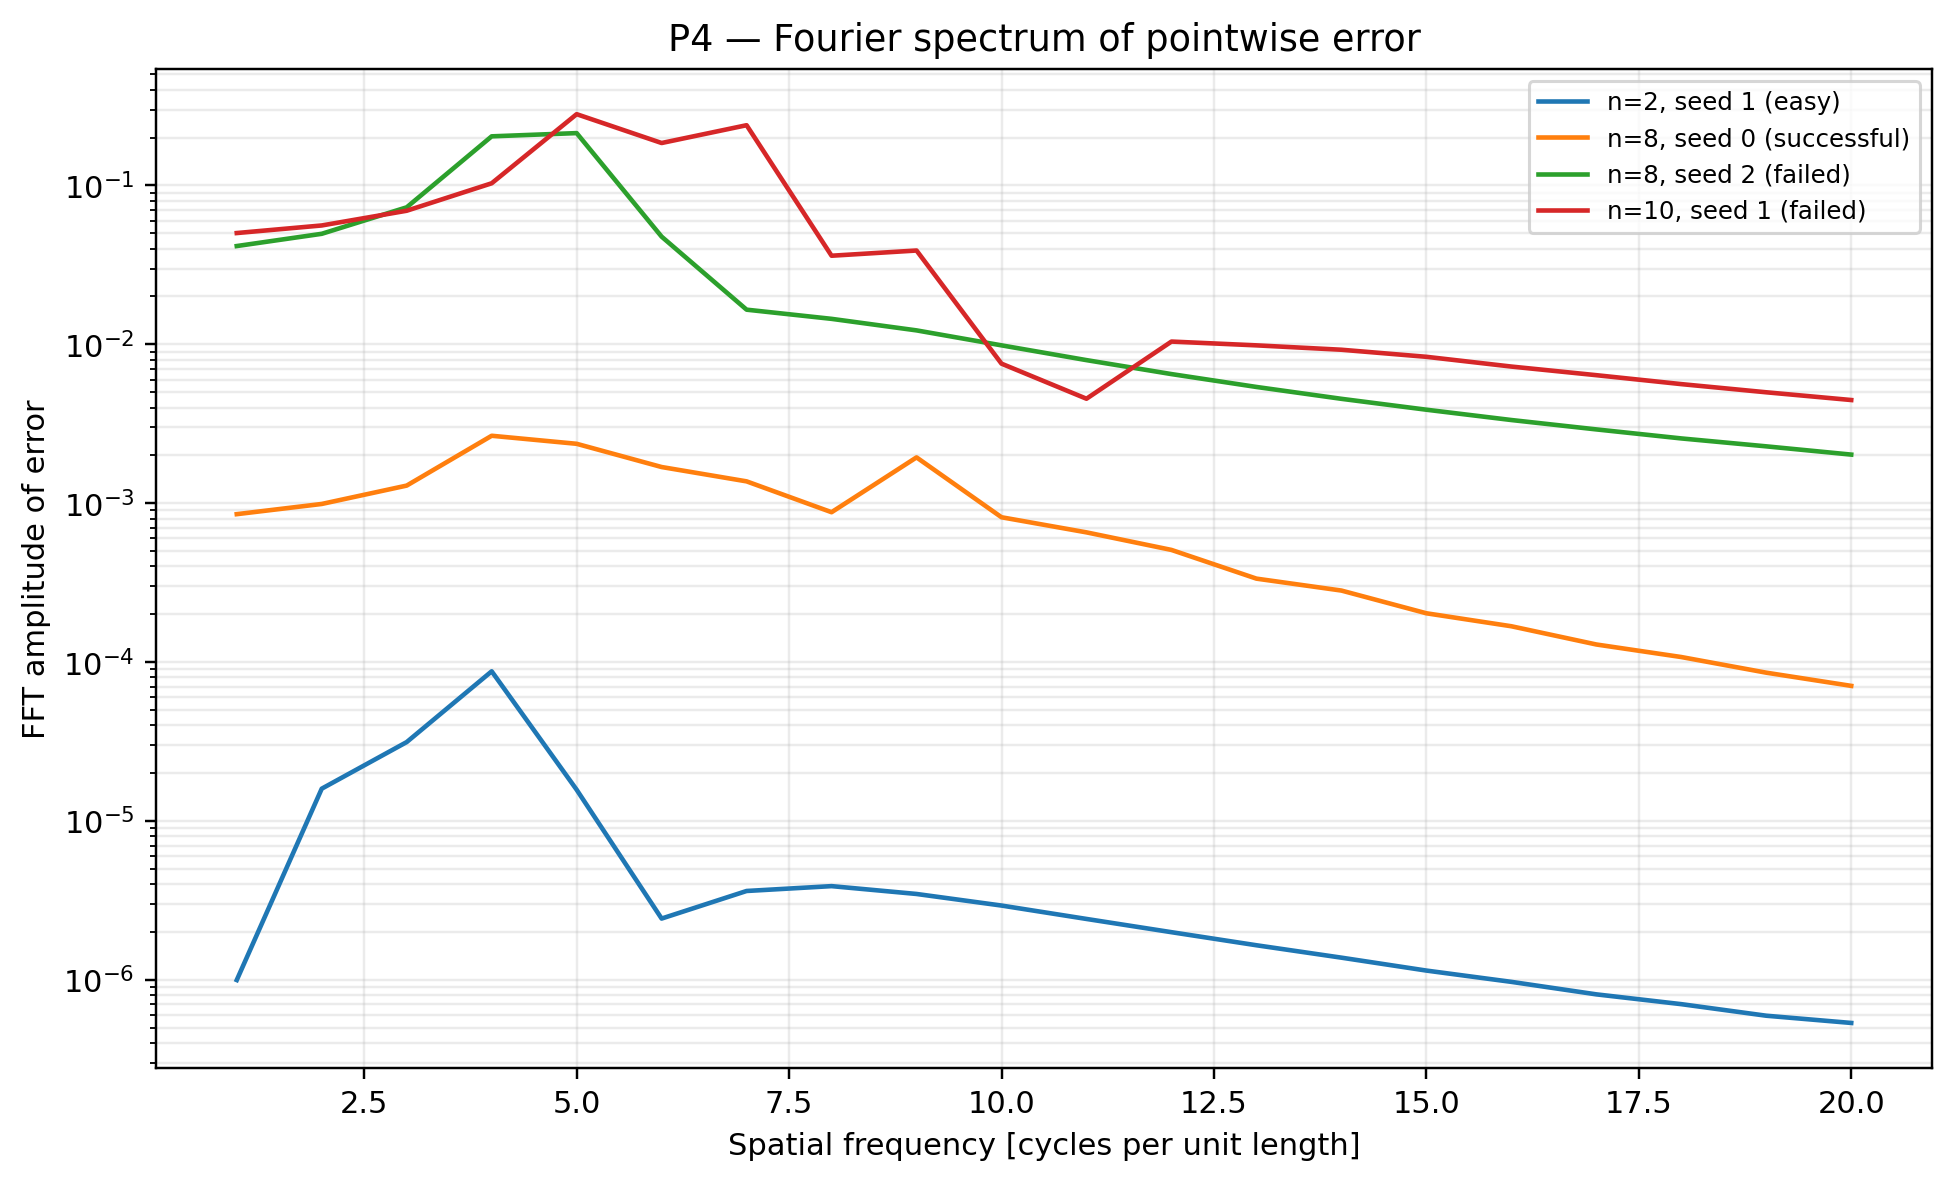

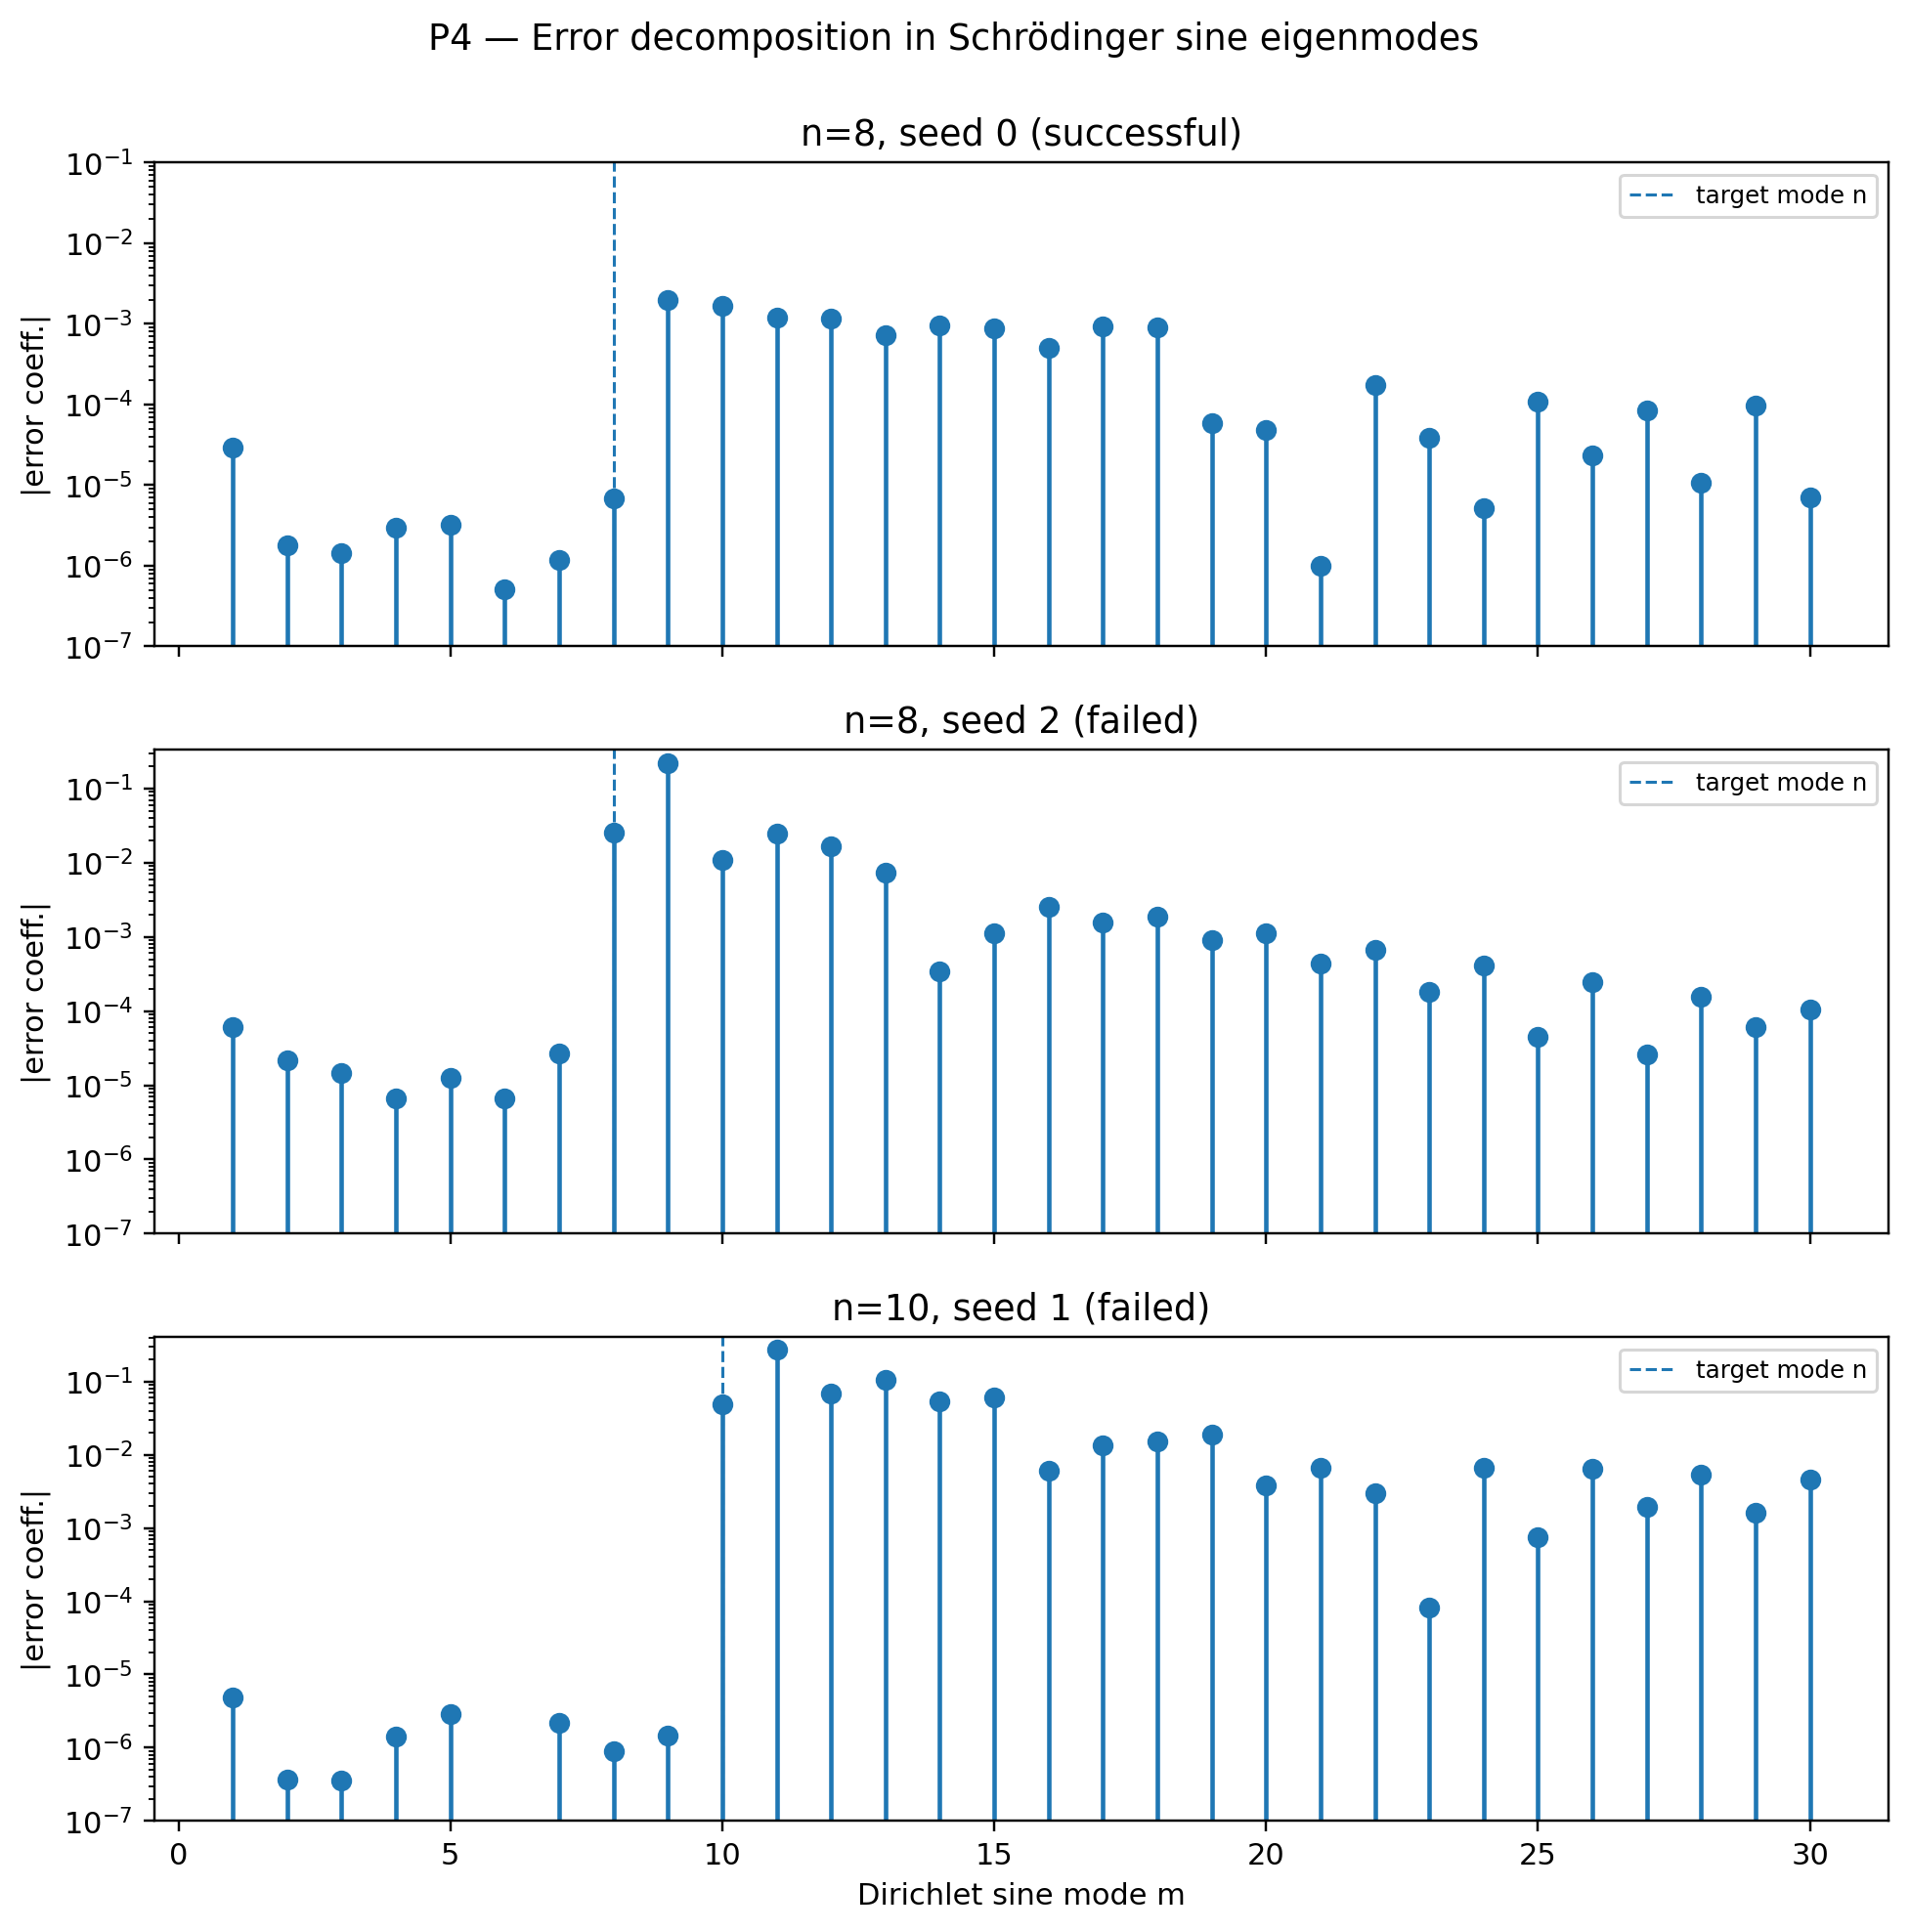

In [12]:
# These plots were generated from saved detailed solution arrays during P4.
for filename in [
    "p4_n8_success_vs_failure.png",
    "p4_fourier_error_spectra.png",
    "p4_sine_mode_error_decomposition.png",
]:
    path = FIGURES_DIR / filename
    if path.exists():
        display(Image(filename=str(path)))
    else:
        print("Missing figure:", path)

### P4 interpretation

The failed but still well-normalized solutions are **not dominated by lower-frequency modes**. For the failed $n=8$ case, about **98.7%** of the captured sine-mode error energy lies above the target mode, with the largest error component near $m=9$. The failed $n=10$ case similarly places about **97.5%** of captured error energy above the target, with the largest error near $m=11$.

Because lower states are projected out, the failure is better described as **distortion of the target and neighboring higher-frequency eigenstructure** than as simple reversion to low-frequency eigenstates.

Combined with the supervised control, P4 does **not** justify the stronger claim that “spectral bias alone causes failure.” A more defensible conclusion is that physics-informed optimization becomes unstable/ill-conditioned for increasingly oscillatory eigenstates and may converge to incorrect mixtures of neighboring high modes.

# 10. P5 — Computational cost

P5 compares the conventional baseline with PINN training and inference. The present PINN is a **per-instance solver**, not a PINO/operator model trained once over a parameter family, so inference cost is reported but a surrogate break-even claim is not treated as meaningful for this fixed single-instance formulation.

,method,scope,setup_or_training_s,query_or_solve_ms,notes
0,Finite difference baseline,Solve first 10 eigenstates at N=1000,0.000000,4.121478,Returns 10 eigenvalues and 10 wavefunctions in...
1,PINN,Train one eigenstate (median across 24 P3 runs),19.309563,NaN,One PINN is trained per target eigenstate/prob...
2,PINN inference,Evaluate one trained n=10 architecture on 1002...,19.309563,0.620189,Architecture-equivalent timing; saved P3 runs ...
3,10 PINN inferences,Evaluate ten separately trained architectures ...,193.095633,4.151058,Requires ten already-trained models; not a sin...


,Recorded environment
cpu,INTEL(R) XEON(R) PLATINUM 8573C
machine,x86_64
python,3.13.5
torch,2.10.0+cpu
scipy,1.17.0
cuda_available,False
torch_threads_for_benchmark,1
logical_cpus_visible,9
fd_grid_interior_points,1000
fd_states_returned,10


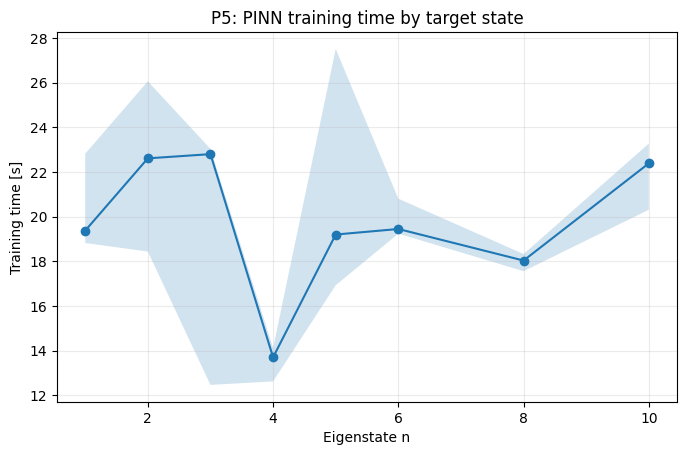

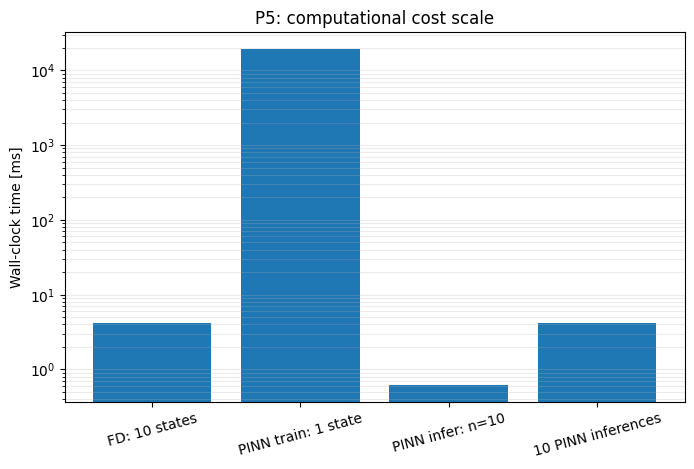

In [13]:
# Load saved cost/benchmark measurements.
p5_cost = pd.read_csv(RESULTS_DIR / "p5_cost_comparison.csv")
p5_hw = pd.read_csv(RESULTS_DIR / "p5_hardware.csv")
p5_inf = pd.read_csv(RESULTS_DIR / "p5_pinn_inference_benchmark.csv")

# Training-time statistics are derived directly from P3 raw results so they always stay consistent.
p5_train = (
    p3.groupby("target_n")["training_time_s"]
      .agg(["median", "mean", "min", "max"])
      .reset_index()
      .rename(columns={
          "median":"median_training_s", "mean":"mean_training_s",
          "min":"min_training_s", "max":"max_training_s"
      })
)

display(p5_cost)
display(p5_hw.T.rename(columns={0: "Recorded environment"}))

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(p5_train.target_n, p5_train.median_training_s, "o-")
ax.fill_between(p5_train.target_n, p5_train.min_training_s, p5_train.max_training_s, alpha=0.2)
ax.set_xlabel("Eigenstate n")
ax.set_ylabel("Training time [s]")
ax.set_title("P5: PINN training time by target state")
ax.grid(alpha=0.25)
plt.show()

labels = ["FD: 10 states", "PINN train: 1 state", "PINN infer: n=10", "10 PINN inferences"]
values = [
    p5_cost.loc[p5_cost.method == "Finite difference baseline", "query_or_solve_ms"].iloc[0],
    1000 * p5_cost.loc[p5_cost.method == "PINN", "setup_or_training_s"].iloc[0],
    p5_cost.loc[p5_cost.method == "PINN inference", "query_or_solve_ms"].iloc[0],
    p5_cost.loc[p5_cost.method == "10 PINN inferences", "query_or_solve_ms"].iloc[0],
]
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(labels, values)
ax.set_yscale("log")
ax.set_ylabel("Wall-clock time [ms]")
ax.set_title("P5: computational cost scale")
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", which="both", alpha=0.25)
plt.show()

### P5 conclusion

The conventional finite-difference solver computes the **first ten states together in about 4.1 ms** on the recorded CPU environment. Median PINN training requires about **19.3 s for one target state**, roughly **4700 times longer** than that complete ten-state finite-difference solve.

PINN inference is inexpensive (sub-millisecond for a single trained network), but evaluating ten separately trained architectures takes roughly the same time as recomputing all ten states conventionally—and the neural models require their training cost beforehand.

Therefore,

$$
\boxed{\text{the PINN provides no computational-cost advantage for this simplified forward eigenproblem.}}
$$

This does **not** rule out neural operators or other surrogates for Dr. Zhuang's real many-query setting, where individual high-fidelity calculations can be vastly more expensive and a model may amortize training cost across many different material configurations.

# 11. Path B findings and recommendation

The evidence forms a consistent chain:

1. **P1 — baseline:** the conventional solver is accurate, convergent, and inexpensive.
2. **P2 — training diagnostics:** low states can be solved accurately; constraint terms remain controlled while the PDE residual becomes difficult in failed high states.
3. **P3 — difficulty sweep:** accuracy and reliability degrade beginning around $n\approx4$, with strong seed sensitivity at higher $n$ and consistent failure by $n=10$.
4. **Controlled experiment:** the same network architecture directly fits $n=4,8,10$ to low error, strongly disfavoring insufficient representational capacity as the primary cause.
5. **P4 — error localization:** failed runs contain distorted neighboring/higher-mode structure rather than merely collapsing to lower eigenstates.
6. **P5 — cost:** a standard PINN is far more expensive than the conventional baseline for this minimal forward problem.

## Overall diagnosis

$$
\boxed{\text{The observed failure is primarily associated with physics-informed optimization, not lack of network capacity.}}
$$

A more detailed mechanism—such as gradient conditioning, loss-landscape structure, or frequency-dependent optimization difficulty—would require additional controlled experiments before being claimed as the sole root cause.

## One-page recommendation memo to Dr. Zhuang

**To:** Dr. Houlong Zhuang  
**From:** **TODO — team member names**  
**Subject:** Recommendation from minimal PINN eigenvalue study

Dr. Zhuang,

Following our conversation about quantum-mechanical eigenvalue calculations, machine-learning surrogates, and the computational cost/accuracy tradeoff in materials modeling, we tested a deliberately simplified one-dimensional Schrödinger eigenvalue problem to examine where a standard physics-informed neural network begins to become unreliable.

Our conventional finite-difference baseline was extremely accurate and inexpensive for this minimal problem. A standard tanh PINN also performed well on low eigenstates, but reliability deteriorated as the target eigenfunction became more oscillatory. States $n=1$ through $3$ were consistently accurate across random initializations, while performance became much less reliable beginning around $n=4$. At $n=8$, identical PINN configurations ranged from approximately 0.36% to 22.4% wavefunction error depending only on initialization. At $n=10$, all three runs failed, with approximately 25–91% error.

We performed a controlled experiment to determine whether this was simply because the neural network was too small to represent the higher-frequency eigenfunctions. The same 1–32–32–1 tanh architecture was trained directly on the analytical $n=4$, $8$, and $10$ solutions. With an extended optimization intended to test representational capacity, every supervised run remained below 0.8% error, including a median error near 0.32% for $n=10$. This indicates that the architecture itself can represent the difficult states; the primary limitation in our experiment is instead associated with physics-informed optimization.

Spatial and spectral error analysis provided additional evidence. Failed high-state solutions were not dominated by lower eigenstates; instead, they developed substantial neighboring and higher-mode distortions. For this simple forward eigenproblem, we therefore would **not recommend a standard PINN as a replacement for a conventional eigenvalue solver**. The finite-difference method solved the first ten states in only a few milliseconds, whereas each PINN required seconds of training and became less reliable as eigenstate complexity increased.

This conclusion should not be generalized directly to your production materials calculations. Our model omits many-electron interactions, realistic potentials, three-dimensional geometry, and the very large computational costs that motivate surrogate modeling in your work. A useful next experiment would be to test a **parameterized surrogate or neural operator across a family of potentials/material configurations**, where training cost can be amortized over many expensive solves, or to investigate targeted PINN remedies for the diagnosed optimization difficulty.

**Confidence:** high for the simplified 1-D test problem; limited for extrapolation to full materials simulations.

**Researcher response:** **TODO — add after memo is sent, if a response is received.**

# 12. Assumptions and limitations

1. **One spatial dimension.** The experiment does not capture 3-D atomic geometry.
2. **Single-particle proxy.** Electron–electron, electron–nuclear, and nuclear–nuclear interactions in the real research problem are not represented.
3. **Infinite square-well potential.** The potential is intentionally much simpler than a real material Hamiltonian.
4. **Analytical lower-state projection.** Known lower eigenfunctions are projected out so the experiment isolates high-state training difficulty instead of state-selection ambiguity.
5. **Fixed small network.** The project diagnoses one standard tanh architecture rather than exhaustively tuning architectures.
6. **Limited optimizer/hyperparameter search.** The objective is diagnosis under controlled settings, not finding the best possible PINN.
7. **Eigenstate number is a proxy difficulty knob.** It captures increasing oscillatory complexity but not the full scaling mechanism caused by many interacting electrons.
8. **CPU timing is hardware dependent.** Cost conclusions for this minimal problem should be interpreted using the recorded hardware and relative scale, not as universal timings.
9. **P5 inference benchmark limitation.** The original P3 experiment did not retain every trained model checkpoint, so the saved inference benchmark measured architecture-equivalent forward/projection operations. Future regenerated runs can save actual checkpoints in `models/`.
10. **No claim of a unique detailed mechanism.** The controlled experiment supports optimization rather than expressivity as the primary limitation; it does not prove that one specific mechanism such as spectral bias alone is responsible.

# 13. Reproducibility and file map

A reader can inspect the saved results immediately or regenerate the experiments with different settings.

```text
.
├── Project3_Report.ipynb
├── requirements.txt
├── config/
│   └── experiment.json
├── src/
│   ├── physics.py
│   ├── finite_difference.py
│   ├── models.py
│   ├── pinn.py
│   ├── supervised.py
│   └── diagnostics.py
├── scripts/
│   ├── run_p1_baseline.py
│   ├── run_p3_sweep.py
│   ├── run_controlled_diagnosis.py
│   ├── run_p4_diagnostics.py
│   └── run_p5_cost.py
├── data/
│   ├── results/
│   └── solutions/
├── models/
└── figures/
```

Install dependencies from the repository root with

```bash
python -m pip install -r requirements.txt
```

To change the experiment, edit `config/experiment.json`. For example, changing

```json
"states": [1, 2, 3, 4, 5, 6, 8, 10]
```

to another list changes the difficulty sweep without rewriting the training implementation.

# 14. References

1. Course Project 3 brief, **“PINN/PINO in the Field.”**
2. Raissi, M., Perdikaris, P., & Karniadakis, G. E. (2019). *Physics-informed neural networks: A deep learning framework for solving forward and inverse problems involving nonlinear partial differential equations.* Journal of Computational Physics, 378, 686–707.
3. Krishnapriyan, A. S., Gholami, A., Zhe, S., Kirby, R. M., & Mahoney, M. W. (2021). *Characterizing possible failure modes in physics-informed neural networks.* NeurIPS 2021.
4. Wang, S., Yu, X., & Perdikaris, P. (2022). *When and why PINNs fail to train: A neural tangent kernel perspective.* Journal of Computational Physics, 449, 110768.
5. Wang, S., Sankaran, S., & Perdikaris, P. (2024). *Respecting causality for training physics-informed neural networks.* Computer Methods in Applied Mechanics and Engineering, 421, 116813.
6. Li, Z., Kovachki, N., Azizzadenesheli, K., et al. (2021). *Fourier neural operator for parametric partial differential equations.* ICLR 2021.

## Final submission checklist

- [ ] Fill in team member names.
- [ ] Fill in exact outreach/interview dates and format.
- [ ] State whether Dr. Zhuang reviewed the problem brief.
- [ ] Send the recommendation memo to Dr. Zhuang.
- [ ] Add his response if one is received.
- [ ] Confirm all repository files are public and no confidential/unpublished researcher data are included.
- [ ] Run the notebook top-to-bottom once after the final GitHub upload.
- [ ] Confirm math and relative figure/file paths render correctly on GitHub.